<table style="width: 100%; border-collapse: collapse; border-bottom: 4px solid #003366;">
    <tr style="border: none;">
        <td style="border: none; text-align: left; vertical-align: middle; padding-bottom: 15px;">
            <h1 style="color: #003366; font-family: 'Helvetica', sans-serif; margin-top: 0; margin-bottom: 5px;">IMT3410: M&eacute;todos para Ecuaciones Diferenciales</h1>
            <h2 style="color: #555; margin-top: 10px; margin-bottom: 10px;">Leyes de conservaci&oacute;n &mdash; modelos y teor&iacute;a</h2>
            <p style="margin: 2px 0;"><b>Profesor:</b> Manuel A. Sánchez </p>
            <p style="margin: 2px 0;"><b>Institución:</b> Instituto de Ingenier&iacute;a Matemática y Computacional, Pontificia Universidad Católica de Chile</p>
        </td>
        <td style="border: none; text-align: right; vertical-align: middle; padding-bottom: 15px; width: 260px;">
            <!-- <img src="../source/FacMatematicas-15.png" alt="Logo UC" width="400" style="margin-bottom: 8px;"> -->
            <br>
            <a href="https://colab.research.google.com/github/ManuelSanchezUribe/ManuelSanchezUribe.github.io/blob/main/IMT3410/Notebooks_2026/03_Capitulo_Leyes_de_conservacion.ipynb" target="_blank">
                <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab" width="120">
            </a>
        </td>
    </tr>
</table>
<br>

**Contenido**
1. Ecuación de advección con coeficiente constante
2. Advección con coeficiente variable: forma advectiva y forma conservativa
3. Ecuación de Burgers: características y quiebre de la onda
4. Problema de Riemann para Burgers: choque, rarefacción, entropía y viscosidad evanescente
5. Primeros experimentos numéricos con diferencias finitas (adelanto de las Clases 25 y 26)
6. Sistemas hiperbólicos lineales: acústica
7. Aguas someras: rotura de presa
8. Dinámica de gases: tubo de choque de Sod
9. Ejercicios

> Las animaciones se muestran con `to_jshtml()`, que funciona en Jupyter y en Colab sin instalar nada. Si trabajas en Jupyter local y quieres gráficos interactivos, puedes usar `%matplotlib widget` (requiere `pip install ipympl`).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from IPython.display import HTML, display
from scipy.optimize import brentq

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})

def animar(x, U, tiempos, exacta=None, ylim=None, paso=1, titulo="", estilo="o-"):
    # Anima una lista de perfiles U[n] (en tiempos[n]); 'exacta(x, t)' es opcional.
    fig, ax = plt.subplots(figsize=(7, 3.5))
    (lnum,) = ax.plot(x, U[0], estilo, ms=2.5, lw=1, label="numérica")
    if exacta is not None:
        (lex,) = ax.plot(x, exacta(x, tiempos[0]), "k-", lw=1.2, label="exacta")
        ax.legend(loc="upper right")
    if ylim is not None:
        ax.set_ylim(*ylim)
    txt = ax.set_title("")
    def actualizar(n):
        lnum.set_ydata(U[n])
        if exacta is not None:
            lex.set_ydata(exacta(x, tiempos[n]))
        txt.set_text(f"{titulo}   t = {tiempos[n]:.3f}")
        return (lnum,)
    ani = animation.FuncAnimation(fig, actualizar, frames=range(0, len(U), paso), interval=60)
    plt.close(fig)
    return HTML(ani.to_jshtml())

## 1. Ecuación de advección: ley de conservación lineal

Analizamos la ecuación de advección en dimensión 1, con **coeficiente de advección constante** $a$:
$$
\frac{\partial u}{\partial t}(x,t) + a \frac{\partial u}{\partial x}(x,t) = 0, \quad x\in (x_L,x_R),\ t\geq 0, \qquad u(x,0)=u_0(x).
$$
La solución es $u(x,t) = u_0(x-at)$: el dato se traslada con velocidad $a$ a lo largo de las **características** $x(t) = x_0 + at$.

In [2]:
# condicion inicial
u0 = lambda x: np.sin(np.pi * x)

# coeficiente de adveccion
a = 1.0

# solucion de la ecuacion de adveccion
u = lambda x, t: u0(x - a * t)

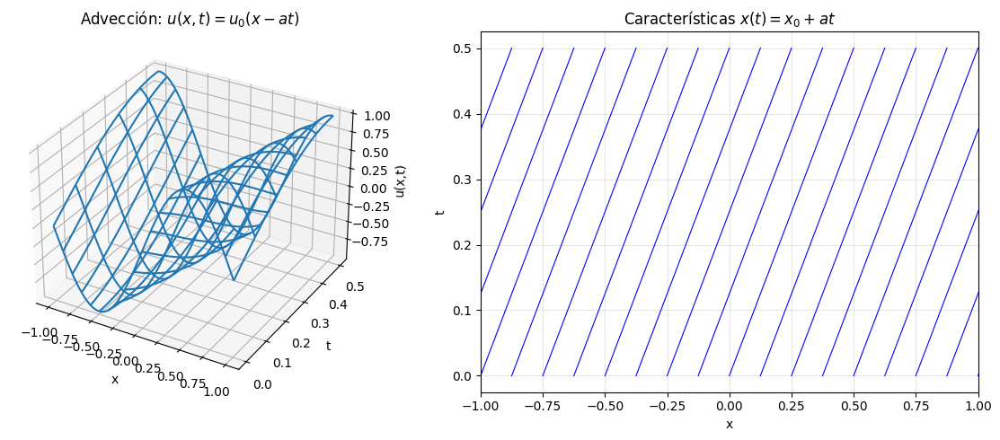

In [3]:
xplot = np.linspace(-1, 1, 200)
tplot = np.linspace(0, 0.5, 50)
X, T = np.meshgrid(xplot, tplot)

fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot_wireframe(X, T, u(X, T), rstride=10, cstride=10)
ax.set(xlabel="x", ylabel="t", zlabel="u(x,t)", title="Advección: $u(x,t)=u_0(x-at)$")

# caracteristicas en el plano x-t
ax2 = fig.add_subplot(1, 2, 2)
for x0 in np.linspace(-1.5, 1, 21):
    ax2.plot(x0 + a * tplot, tplot, "b-", lw=0.8)
ax2.set(xlim=(-1, 1), xlabel="x", ylabel="t", title="Características $x(t)=x_0+at$")
plt.tight_layout(); plt.show()

## 2. Advección con coeficiente variable

Con $a(x) = \frac{1}{\pi}\sin(\pi x - 1)$ en $[-1,1]$ (periódico) y $u_0(x)=\sin(\pi x)$ hay **dos** ecuaciones distintas:

* **Forma advectiva** (ecuación de *color*): $\ u_t + a(x)\,u_x = 0$. La solución es **constante** a lo largo de las características $x'(t) = a(x)$.
* **Forma conservativa** (ley de conservación): $\ u_t + \big(a(x)\,u\big)_x = 0$. A lo largo de las características $\frac{d}{dt}u = -a'(x)\,u$, de modo que se conserva el producto $a(x)\,u$.

Con $\theta = \pi x - 1$, las características satisfacen $\theta' = \sin\theta$, es decir $\tan(\theta/2) = e^{t}\tan(\theta_0/2)$. Por lo tanto
$$
u_{\rm adv}(x,t) = \sin\!\Big(2\arctan\big(e^{-t}\tan\tfrac{\pi x-1}{2}\big)+1\Big),\qquad
u_{\rm cons}(x,t) = u_{\rm adv}(x,t)\,\frac{a(x_0)}{a(x)} = u_{\rm adv}(x,t)\,\frac{e^{-t}(1+\tau^2)}{1+e^{-2t}\tau^2},\quad \tau=\tan\tfrac{\pi x-1}{2}.
$$
La fórmula del notebook original corresponde a la **forma advectiva**.

In [4]:
a_var = lambda x: (1 / np.pi) * np.sin(np.pi * x - 1)
u0 = lambda x: np.sin(np.pi * x)

def u_adv(x, t):
    # forma advectiva u_t + a(x) u_x = 0: u es constante en las caracteristicas
    return np.sin(2 * np.arctan(np.exp(-t) * np.tan((np.pi * x - 1) / 2)) + 1)

def u_cons(x, t):
    # forma conservativa u_t + (a(x) u)_x = 0: a(x) u es constante en las caracteristicas
    tau = np.tan((np.pi * x - 1) / 2)
    return u_adv(x, t) * np.exp(-t) * (1 + tau**2) / (1 + np.exp(-2 * t) * tau**2)

# verificacion: residuo de cada ecuacion con diferencias centradas (lejos del punto donde tan es singular)
xs = np.linspace(-0.5, 0.9, 400); ts = 0.7; d = 1e-5
ux = lambda w: (w(xs + d, ts) - w(xs - d, ts)) / (2 * d)
ut = lambda w: (w(xs, ts + d) - w(xs, ts - d)) / (2 * d)
res_adv = ut(u_adv) + a_var(xs) * ux(u_adv)
au = lambda x, t: a_var(x) * u_cons(x, t)
res_cons = ut(u_cons) + (au(xs + d, ts) - au(xs - d, ts)) / (2 * d)
print(f"residuo forma advectiva:    {np.max(np.abs(res_adv)):.2e}")
print(f"residuo forma conservativa: {np.max(np.abs(res_cons)):.2e}")
print(f"(la formula advectiva NO resuelve la conservativa: residuo {np.max(np.abs(ut(u_adv) + (a_var(xs+d)*u_adv(xs+d,ts) - a_var(xs-d)*u_adv(xs-d,ts))/(2*d))):.2e})")

residuo forma advectiva:    6.23e-10
residuo forma conservativa: 2.25e-09
(la formula advectiva NO resuelve la conservativa: residuo 8.74e-01)


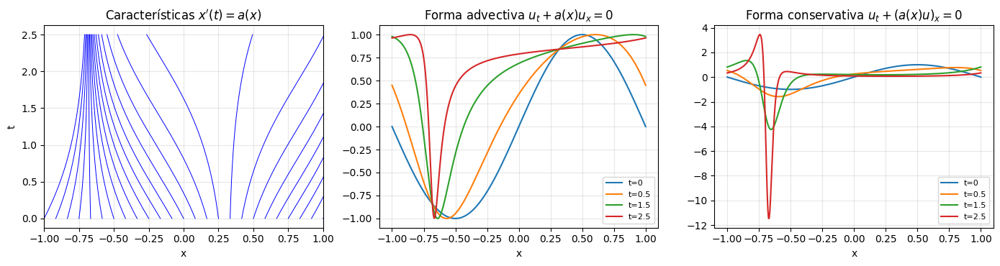

In [5]:
xplot = np.linspace(-1, 1, 400)
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
# caracteristicas: integramos x' = a(x) con Euler fino
for x0 in np.linspace(-1, 1, 25):
    xt, tt = [x0], [0.0]
    for _ in range(250):
        xt.append(xt[-1] + 0.01 * a_var(xt[-1])); tt.append(tt[-1] + 0.01)
    axs[0].plot(xt, tt, "b-", lw=0.7)
axs[0].set(xlim=(-1, 1), xlabel="x", ylabel="t", title="Características $x'(t)=a(x)$")
for t in [0, 0.5, 1.5, 2.5]:
    axs[1].plot(xplot, u_adv(xplot, t), label=f"t={t}")
    axs[2].plot(xplot, u_cons(xplot, t), label=f"t={t}")
axs[1].set(title="Forma advectiva $u_t+a(x)u_x=0$", xlabel="x"); axs[1].legend(fontsize=8)
axs[2].set(title="Forma conservativa $u_t+(a(x)u)_x=0$", xlabel="x"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Observación.** En la forma conservativa la masa $\int u\,dx$ se conserva, pero se **concentra** donde las características convergen ($a=0$ con $a'<0$): el máximo crece como $e^{t}$. En la forma advectiva los valores sólo se transportan.

## 3. Ecuación de Burgers: ley de conservación no lineal

$$
\frac{\partial u}{\partial t} + \frac{\partial}{\partial x}\Big(\frac{u^2}{2}\Big) = 0, \qquad u(x,0)=u_0(x).
$$
Las características son rectas $x(t) = x_0 + u_0(x_0)\,t$ y la solución satisface la ecuación implícita $u = u_0(x - u\,t)$.
Por el teorema de la función implícita, $u_x = u_0'/(1+u_0' t)$: si $u_0'<0$ en algún punto, la derivada explota en el **tiempo de quiebre**
$$
T_b = \frac{-1}{\min_x u_0'(x)}.
$$
Para $u_0(x) = -\sin(\pi x)$ se tiene $\min u_0' = -\pi$, luego $T_b = 1/\pi \approx 0.318$.

In [6]:
u0 = lambda x: -np.sin(np.pi * x)
du0 = lambda x: -np.pi * np.cos(np.pi * x)
Tb = 1 / np.pi

def burgers_implicita(x, t, iters=60):
    # Resuelve u = u0(x - u t) por Newton (vectorizado). Valido para t < T_b.
    u = u0(x)
    for _ in range(iters):
        g = u - u0(x - u * t)
        dg = 1 + du0(x - u * t) * t
        u = u - g / dg
    return u

print(f"T_b = {Tb:.4f}")

T_b = 0.3183


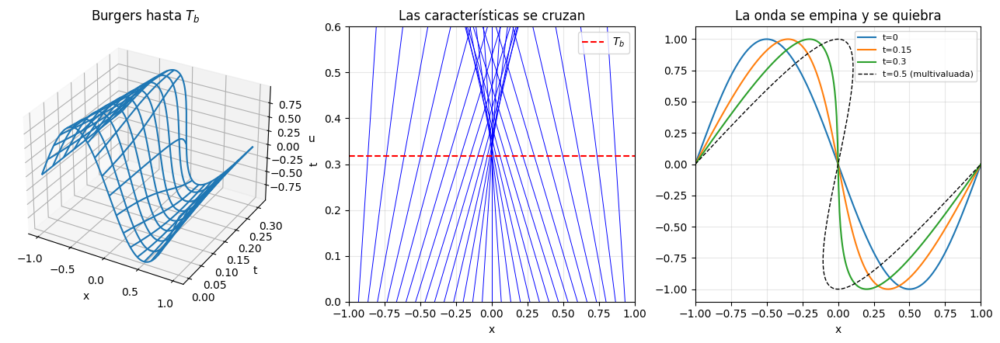

In [7]:
xplot = np.linspace(-1, 1, 300)
tplot = np.linspace(0, 0.98 * Tb, 40)
X, T = np.meshgrid(xplot, tplot)
Z = burgers_implicita(X, T)

fig = plt.figure(figsize=(13, 4.5))
ax = fig.add_subplot(1, 3, 1, projection="3d")
ax.plot_wireframe(X, T, Z, rstride=5, cstride=15)
ax.set(xlabel="x", ylabel="t", zlabel="u", title="Burgers hasta $T_b$")

ax2 = fig.add_subplot(1, 3, 2)
for x0 in np.linspace(-1, 1, 31):
    ax2.plot(x0 + u0(x0) * np.array([0, 0.6]), [0, 0.6], "b-", lw=0.7)
ax2.axhline(Tb, color="r", ls="--", label="$T_b$")
ax2.set(xlim=(-1, 1), ylim=(0, 0.6), xlabel="x", ylabel="t", title="Las características se cruzan")
ax2.legend()

ax3 = fig.add_subplot(1, 3, 3)
for t in [0, 0.15, 0.3]:
    ax3.plot(xplot, burgers_implicita(xplot, t), label=f"t={t}")
# despues de T_b: la "solucion" por caracteristicas es multivaluada
x0 = np.linspace(-1, 1, 600); t = 0.5
ax3.plot(x0 + u0(x0) * t, u0(x0), "k--", lw=1, label="t=0.5 (multivaluada)")
ax3.set(xlim=(-1, 1), xlabel="x", title="La onda se empina y se quiebra"); ax3.legend(fontsize=8)
plt.tight_layout(); plt.show()

Después de $T_b$ las características se cruzan y la "solución" por características es **multivaluada** (curva punteada). Hay que admitir discontinuidades: **soluciones débiles**.

## 4. Problema de Riemann para Burgers

$$
u_t + (u^2/2)_x = 0,\qquad u_0(x) = \begin{cases} u_L & x<0,\\ u_R & x\ge 0.\end{cases}
$$

* Si $u_L > u_R$: **choque** que viaja con la velocidad de Rankine–Hugoniot $s = \dfrac{[f]}{[u]} = \dfrac{u_L+u_R}{2}$.
* Si $u_L < u_R$: hay infinitas soluciones débiles; la de **entropía** es la **rarefacción** $u = x/t$ para $u_L t \le x \le u_R t$. El "choque" con velocidad $s$ también es solución débil, pero viola la condición de entropía $f'(u_L) > s > f'(u_R)$.

In [8]:
def riemann_burgers(x, t, uL, uR):
    # Solucion de entropia del problema de Riemann para Burgers.
    x = np.asarray(x, dtype=float)
    if t == 0:
        return np.where(x < 0, uL, uR)
    if uL > uR:                       # choque
        s = 0.5 * (uL + uR)
        return np.where(x < s * t, uL, uR)
    xi = x / t                        # rarefaccion
    return np.where(xi < uL, uL, np.where(xi > uR, uR, xi))

def choque_no_entropico(x, t, uL, uR):
    s = 0.5 * (uL + uR)
    return np.where(np.asarray(x) < s * t, uL, uR)

def caracteristicas(ax, uL, uR, sol, T=0.5, titulo=""):
    # dibuja las caracteristicas x0 + u(x0) t, cortadas donde corresponda segun 'sol'
    tt = np.linspace(0, T, 200)
    for x0 in np.linspace(-1, 1, 25):
        u_x0 = uL if x0 < 0 else uR
        xs = x0 + u_x0 * tt
        # mantenemos solo los tramos donde la solucion vale u_x0 (antes de chocar)
        ok = np.isclose(sol(xs, tt), u_x0) | (tt == 0)
        ax.plot(np.where(ok, xs, np.nan), tt, "g-", lw=0.7)
    ax.set(xlim=(-1, 1), ylim=(0, T), xlabel="x", ylabel="t", title=titulo)

sol_vec = lambda f: np.vectorize(f)

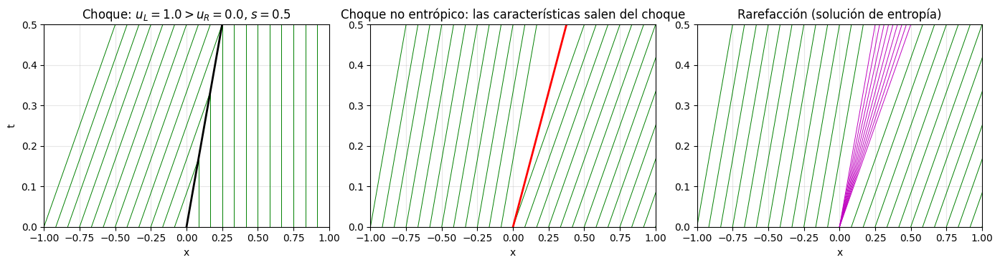

In [9]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
x = np.linspace(-1, 1, 400); T = 0.5

# (a) choque u_L > u_R
uL, uR = 1.0, 0.0; s = 0.5 * (uL + uR)
caracteristicas(axs[0], uL, uR, sol_vec(lambda xx, tt: riemann_burgers(xx, tt, uL, uR)), T,
                f"Choque: $u_L={uL}>u_R={uR}$, $s={s}$")
axs[0].plot(s * np.linspace(0, T), np.linspace(0, T), "k-", lw=2)

# (b) choque NO entropico u_L < u_R
uL, uR = 0.5, 1.0; s = 0.5 * (uL + uR)
tt = np.linspace(0, T, 200)
for x0 in np.linspace(-1, 1, 25):
    u_x0 = uL if x0 < 0 else uR
    axs[1].plot(x0 + u_x0 * tt, tt, "g-", lw=0.7)
axs[1].plot(s * tt, tt, "r-", lw=2)
axs[1].set(xlim=(-1, 1), ylim=(0, T), xlabel="x", title="Choque no entrópico: las características salen del choque")

# (c) rarefaccion u_L < u_R
for x0 in np.linspace(-1, 1, 25):
    u_x0 = uL if x0 < 0 else uR
    if x0 != 0:
        axs[2].plot(x0 + u_x0 * tt, tt, "g-", lw=0.7)
for xi in np.linspace(uL, uR, 9):
    axs[2].plot(xi * tt, tt, "m-", lw=0.7)
axs[2].set(xlim=(-1, 1), ylim=(0, T), xlabel="x", title="Rarefacción (solución de entropía)")
plt.tight_layout(); plt.show()

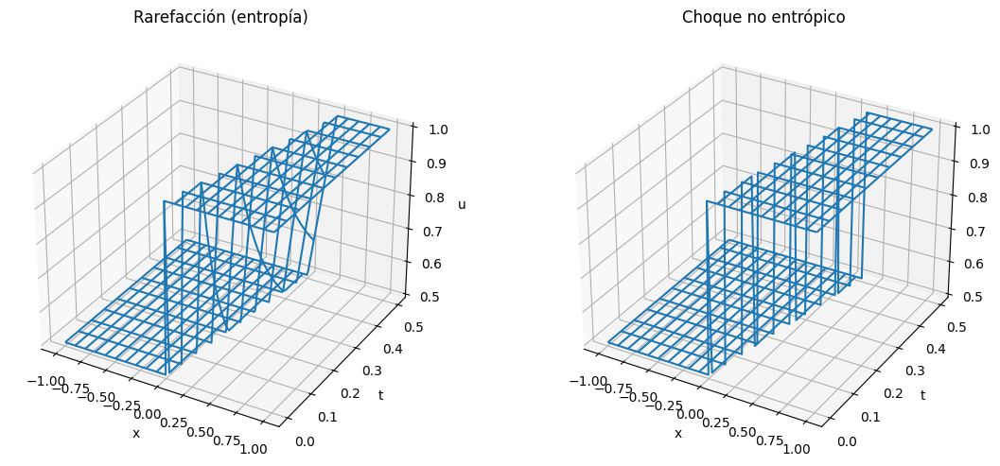

Rankine-Hugoniot:  s (u_L - u_R) = 0.5   f(u_L) - f(u_R) = 0.5


In [10]:
# superficies u(x,t): rarefaccion (entropica) vs choque no entropico, como en el notebook original (u_L=0.5, u_R=1)
uL, uR = 0.5, 1.0
xplot = np.linspace(-1, 1, 200); tplot = np.linspace(1e-3, 0.5, 50)
X, T = np.meshgrid(xplot, tplot)
Zrar = np.array([riemann_burgers(xplot, t, uL, uR) for t in tplot])
Zcho = np.array([choque_no_entropico(xplot, t, uL, uR) for t in tplot])

fig = plt.figure(figsize=(12, 5))
for k, (Z, tit) in enumerate([(Zrar, "Rarefacción (entropía)"), (Zcho, "Choque no entrópico")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.plot_wireframe(X, T, Z, rstride=5, cstride=10)
    ax.set(xlabel="x", ylabel="t", zlabel="u", title=tit)
plt.tight_layout(); plt.show()

# Rankine-Hugoniot: s [u] = [f]
f = lambda u: u**2 / 2
uL, uR = 1.0, 0.0; s = 0.5 * (uL + uR)
print("Rankine-Hugoniot:  s (u_L - u_R) =", s * (uL - uR), "  f(u_L) - f(u_R) =", f(uL) - f(uR))

### Viscosidad evanescente

La solución de entropía es el límite cuando $\varepsilon\to 0$ de $u_t + u u_x = \varepsilon u_{xx}$. Para $u_L>u_R$ hay una onda viajera exacta
$$
u^\varepsilon(x,t) = w(x-st),\qquad w(y) = u_R + \frac{u_L-u_R}{2}\Big(1-\tanh\frac{(u_L-u_R)\,y}{4\varepsilon}\Big),
$$
que converge al choque. El ancho de la transición es $\mathcal O(\varepsilon)$.

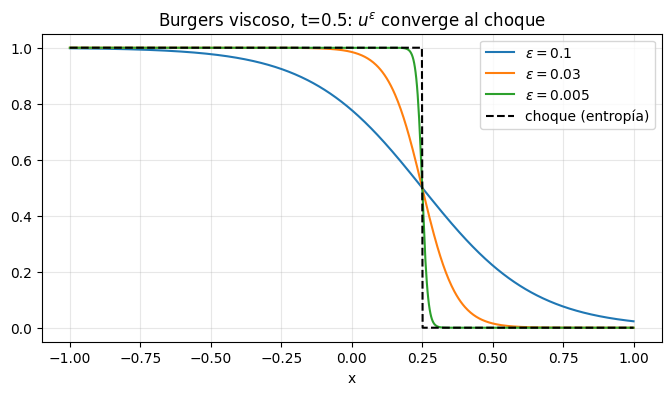

In [11]:
uL, uR = 1.0, 0.0; s = 0.5 * (uL + uR); t = 0.5
x = np.linspace(-1, 1, 800)
w = lambda y, eps: uR + 0.5 * (uL - uR) * (1 - np.tanh((uL - uR) * y / (4 * eps)))
for eps in [0.1, 0.03, 0.005]:
    plt.plot(x, w(x - s * t, eps), label=f"$\\varepsilon={eps}$")
plt.plot(x, riemann_burgers(x, t, uL, uR), "k--", label="choque (entropía)")
plt.title(f"Burgers viscoso, t={t}: $u^\\varepsilon$ converge al choque"); plt.xlabel("x"); plt.legend(); plt.show()

## 5. Primeros experimentos numéricos con diferencias finitas

Adelanto de las Clases 25 y 26. Usamos una malla uniforme $x_j = x_L + jh$ y número de Courant $\nu = a\Delta t/h$.
Para el problema periódico con $N$ nodos en $[x_L, x_R)$ el paso es $h = (x_R-x_L)/N$.

| Método | Esquema |
|---|---|
| Centrado (FTCS) | $u_j^{n+1} = u_j^n - \frac{\nu}{2}(u_{j+1}^n-u_{j-1}^n)$ |
| Lax–Friedrichs | $u_j^{n+1} = \frac12(u_{j-1}^n+u_{j+1}^n) - \frac{\nu}{2}(u_{j+1}^n-u_{j-1}^n)$ |
| Upwind ($a>0$) | $u_j^{n+1} = u_j^n - \nu(u_j^n-u_{j-1}^n)$ |
| Lax–Wendroff | $u_j^{n+1} = u_j^n - \frac{\nu}{2}(u_{j+1}^n-u_{j-1}^n) + \frac{\nu^2}{2}(u_{j+1}^n-2u_j^n+u_{j-1}^n)$ |
| Leap-frog | $u_j^{n+1} = u_j^{n-1} - \nu(u_{j+1}^n-u_{j-1}^n)$ |

In [12]:
def paso(metodo, U, nu, Uant=None):
    # Un paso de tiempo en malla periodica (np.roll implementa la periodicidad).
    Up, Um = np.roll(U, -1), np.roll(U, 1)          # u_{j+1}, u_{j-1}
    if metodo == "centrado":
        return U - nu / 2 * (Up - Um)
    if metodo == "lax-friedrichs":
        return 0.5 * (Up + Um) - nu / 2 * (Up - Um)
    if metodo == "upwind":
        return U - nu * (U - Um)
    if metodo == "lax-wendroff":
        return U - nu / 2 * (Up - Um) + nu**2 / 2 * (Up - 2 * U + Um)
    if metodo == "leap-frog":
        return Uant - nu * (Up - Um)
    raise ValueError(metodo)

def resolver_periodico(metodo, u0, a, intervalo, N, T, CFL=0.8):
    xL, xR = intervalo
    h = (xR - xL) / N
    x = xL + h * np.arange(N)
    dt = CFL * h / abs(a); nu = a * dt / h
    U = [u0(x)]; tiempos = [0.0]
    if metodo == "leap-frog":                      # primer paso con la solucion exacta
        U.append(u0(x - a * dt)); tiempos.append(dt)
    while tiempos[-1] + dt / 2 < T:
        Uant = U[-2] if len(U) > 1 else None
        U.append(paso(metodo, U[-1], nu, Uant)); tiempos.append(tiempos[-1] + dt)
    return x, U, np.array(tiempos)

### Problema 1: onda sinusoidal
$u_0(x) = \sin(2\pi x)$ en $[0,1)$ periódico, $a=1$; la solución exacta es $u(x,t) = \sin(2\pi(x-t))$.
El esquema centrado es **inestable para todo** $\Delta t/h$; leap-frog es estable sólo si $|\nu|<1$.

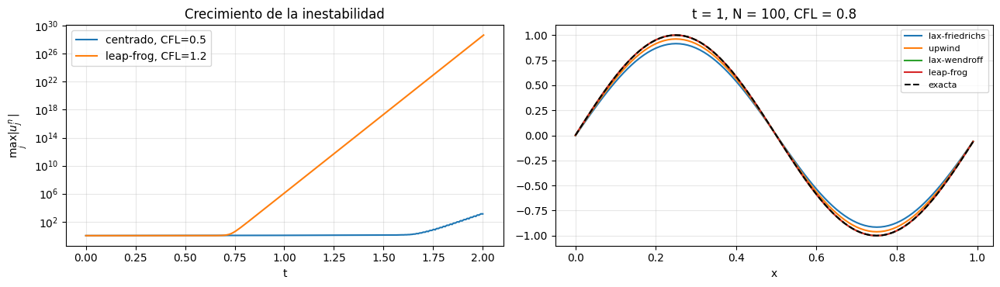

lax-friedrichs  error max = 8.495e-02
upwind          error max = 3.871e-02
lax-wendroff    error max = 1.487e-03
leap-frog       error max = 1.478e-03


In [13]:
u0 = lambda x: np.sin(2 * np.pi * x); a = 1.0
exacta = lambda x, t: u0(x - a * t)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for metodo, CFL in [("centrado", 0.5), ("leap-frog", 1.2)]:
    x, U, tt = resolver_periodico(metodo, u0, a, (0, 1), 100, T=2.0, CFL=CFL)
    normas = [np.max(np.abs(Un)) for Un in U]
    axs[0].semilogy(tt, normas, label=f"{metodo}, CFL={CFL}")
axs[0].set(xlabel="t", ylabel=r"$\max_j |u_j^n|$", title="Crecimiento de la inestabilidad"); axs[0].legend()

errores = {}
for metodo in ["lax-friedrichs", "upwind", "lax-wendroff", "leap-frog"]:
    x, U, tt = resolver_periodico(metodo, u0, a, (0, 1), 100, T=1.0, CFL=0.8)
    axs[1].plot(x, U[-1], label=metodo)
    errores[metodo] = np.max(np.abs(U[-1] - exacta(x, tt[-1])))
axs[1].plot(x, exacta(x, tt[-1]), "k--", label="exacta")
axs[1].set(xlabel="x", title="t = 1, N = 100, CFL = 0.8"); axs[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for m, e in errores.items():
    print(f"{m:15s} error max = {e:.3e}")

In [14]:
# animacion: Lax-Friedrichs vs exacta
x, U, tt = resolver_periodico("lax-friedrichs", u0, a, (0, 1), 100, T=2.0, CFL=0.8)
animar(x, U, tt, exacta=exacta, ylim=(-1.2, 1.2), paso=2, titulo="Lax-Friedrichs")

### Problema 2: dos gaussianas (difusión vs. dispersión)
$u_0(x) = e^{-20(x-2)^2} + e^{-(x-5)^2}$ en $[0,25)$, $a=1$, $h = 0.05$, $\Delta t = 0.8h$, $t = 17$ (el mismo experimento de la Clase 25).
Upwind y Lax–Friedrichs **difunden** (bajan los picos); Lax–Wendroff y leap-frog **dispersan** (oscilaciones detrás del pulso angosto).

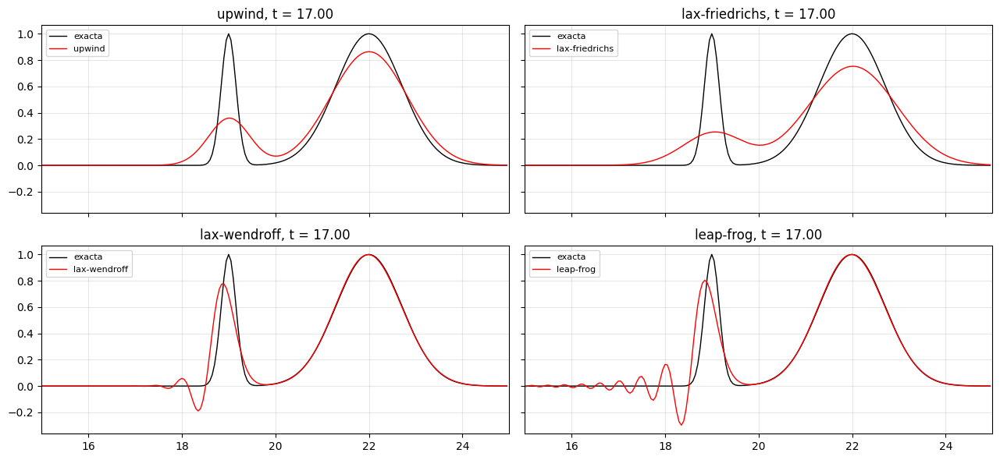

In [15]:
u0 = lambda x: np.exp(-20 * (x - 2)**2) + np.exp(-(x - 5)**2); a = 1.0
exacta = lambda x, t: u0(x - a * t)
N = 500   # h = 25/500 = 0.05

fig, axs = plt.subplots(2, 2, figsize=(13, 6), sharex=True, sharey=True)
for ax, metodo in zip(axs.flat, ["upwind", "lax-friedrichs", "lax-wendroff", "leap-frog"]):
    x, U, tt = resolver_periodico(metodo, u0, a, (0, 25), N, T=17, CFL=0.8)
    ax.plot(x, exacta(x, tt[-1]), "k-", lw=1, label="exacta")
    ax.plot(x, U[-1], "r-", lw=1, label=metodo)
    ax.set(xlim=(15, 25), title=f"{metodo}, t = {tt[-1]:.2f}"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### Problema 3: solución discontinua con frontera de entrada
$u_t + u_x = 0$ en $(-1,1)$, $u_0 = 1$ si $x<0$ y $0$ si $x\ge 0$, dato de entrada $u(-1,t) = 1$. En la frontera de salida usamos upwind.

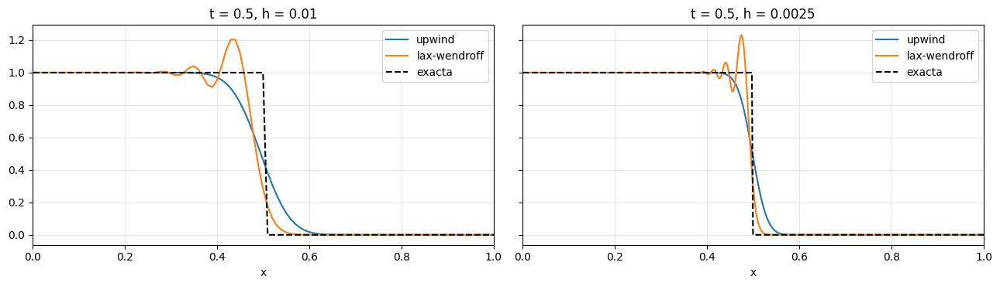

In [16]:
def resolver_frontera(metodo, u0, g0, a, intervalo, N, T, CFL=0.5):
    # Nodos x_j = x_L + j h, j = 0..N, h = (x_R - x_L)/N. Entrada en x_L (a > 0), salida upwind en x_R.
    xL, xR = intervalo
    h = (xR - xL) / N; x = xL + h * np.arange(N + 1)
    dt = CFL * h / a; nu = a * dt / h
    U = [u0(x)]; tiempos = [0.0]
    while tiempos[-1] + dt / 2 < T:
        V = U[-1]; W = np.empty_like(V); t = tiempos[-1] + dt
        Vp, Vm = V[2:], V[:-2]; Vc = V[1:-1]
        if metodo == "upwind":
            W[1:-1] = Vc - nu * (Vc - Vm)
        elif metodo == "lax-friedrichs":
            W[1:-1] = 0.5 * (Vp + Vm) - nu / 2 * (Vp - Vm)
        elif metodo == "lax-wendroff":
            W[1:-1] = Vc - nu / 2 * (Vp - Vm) + nu**2 / 2 * (Vp - 2 * Vc + Vm)
        W[0] = g0(t)                               # frontera de entrada
        W[-1] = V[-1] - nu * (V[-1] - V[-2])       # frontera de salida (upwind)
        U.append(W); tiempos.append(t)
    return x, U, np.array(tiempos)

u0 = lambda x: np.where(x < 0, 1.0, 0.0); g0 = lambda t: 1.0; a = 1.0
exacta = lambda x, t: u0(x - a * t)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, N in zip(axs, [200, 800]):
    for metodo in ["upwind", "lax-wendroff"]:
        x, U, tt = resolver_frontera(metodo, u0, g0, a, (-1, 1), N, T=0.5, CFL=0.5)
        ax.plot(x, U[-1], label=metodo)
    ax.plot(x, exacta(x, tt[-1]), "k--", label="exacta")
    ax.set(xlim=(0, 1), title=f"t = 0.5, h = {2/N}", xlabel="x"); ax.legend()
plt.tight_layout(); plt.show()

Upwind suaviza la discontinuidad (ancho $\sim\sqrt{h\,t}$); Lax–Wendroff es de segundo orden y **oscila** cerca de ella.

### Problema 4: Burgers — la forma conservativa importa
Comparamos el upwind **no conservativo** $u_j^{n+1} = u_j^n - \frac{\Delta t}{h}u_j^n(u_j^n-u_{j-1}^n)$ con un método **conservativo** $u_j^{n+1} = u_j^n - \frac{\Delta t}{h}(F_{j+1/2}-F_{j-1/2})$.
Usamos el flujo de **Godunov** para Burgers, $F(u_L,u_R) = \max\big(f(\max(u_L,0)),\, f(\min(u_R,0))\big)$, y también el flujo "upwind ingenuo" $F = f(u_L)$ si $u_L+u_R\ge 0$, $F=f(u_R)$ si no.

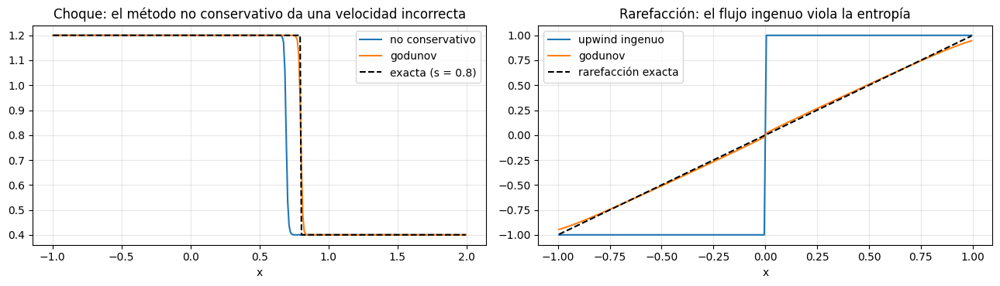

In [17]:
f = lambda u: 0.5 * u**2

def flujo_godunov(uL, uR):
    return np.maximum(f(np.maximum(uL, 0)), f(np.minimum(uR, 0)))

def flujo_upwind_ingenuo(uL, uR):
    return np.where(uL + uR >= 0, f(uL), f(uR))

def burgers(metodo, u0, intervalo, N, T, CFL=0.5):
    # Burgers con condiciones de borde de extrapolacion (valores constantes en los extremos).
    xL, xR = intervalo; h = (xR - xL) / N
    x = xL + h * (np.arange(N) + 0.5)
    U = u0(x); t = 0.0
    while t < T - 1e-12:
        dt = min(CFL * h / max(np.max(np.abs(U)), 1e-12), T - t)
        Ue = np.concatenate([[U[0]], U, [U[-1]]])
        if metodo == "no conservativo":            # supone u >= 0
            U = U - dt / h * U * (U - Ue[:-2])
        else:
            F = (flujo_godunov if metodo == "godunov" else flujo_upwind_ingenuo)(Ue[:-1], Ue[1:])
            U = U - dt / h * (F[1:] - F[:-1])
        t += dt
    return x, U

# (a) choque u_L = 1.2 > u_R = 0.4 (s = 0.8)
uL, uR, T = 1.2, 0.4, 1.0
u0 = lambda x: np.where(x < 0, uL, uR)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for metodo in ["no conservativo", "godunov"]:
    x, U = burgers(metodo, u0, (-1, 2), 300, T)
    axs[0].plot(x, U, label=metodo)
axs[0].plot(x, riemann_burgers(x, T, uL, uR), "k--", label="exacta (s = 0.8)")
axs[0].set(title="Choque: el método no conservativo da una velocidad incorrecta", xlabel="x"); axs[0].legend()

# (b) rarefaccion u_L = -1 < u_R = 1: el flujo ingenuo produce un choque estacionario NO entropico
uL, uR = -1.0, 1.0
u0 = lambda x: np.where(x < 0, uL, uR)
for metodo in ["upwind ingenuo", "godunov"]:
    x, U = burgers(metodo, u0, (-1, 1), 200, T)
    axs[1].plot(x, U, label=metodo)
axs[1].plot(x, riemann_burgers(x, T, uL, uR), "k--", label="rarefacción exacta")
axs[1].set(title="Rarefacción: el flujo ingenuo viola la entropía", xlabel="x"); axs[1].legend()
plt.tight_layout(); plt.show()

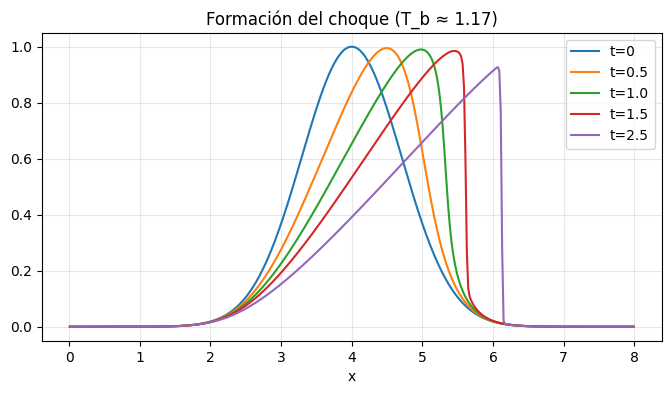

In [18]:
# Burgers suave que forma un choque: u0 = exp(-(x-4)^2) en [0, 8], metodo de Godunov
u0 = lambda x: np.exp(-(x - 4)**2)
fig, ax = plt.subplots()
for T in [0, 0.5, 1.0, 1.5, 2.5]:
    x, U = burgers("godunov", u0, (0, 8), 400, T)
    ax.plot(x, U, label=f"t={T}")
Tb = -1 / np.min(np.gradient(u0(x), x))
ax.set(title=f"Formación del choque (T_b ≈ {Tb:.2f})", xlabel="x"); ax.legend(); plt.show()

## 6. Sistemas hiperbólicos lineales: acústica

$$
\frac{\partial}{\partial t}\begin{bmatrix}p\\ v\end{bmatrix} + \begin{bmatrix}0 & K\\ 1/\rho_0 & 0\end{bmatrix}\frac{\partial}{\partial x}\begin{bmatrix}p\\ v\end{bmatrix} = 0,
\qquad \lambda_{1,2} = \mp c,\ c=\sqrt{K/\rho_0},\qquad r_1 = \begin{bmatrix}-Z\\ 1\end{bmatrix},\ r_2 = \begin{bmatrix}Z\\ 1\end{bmatrix},\ Z = \rho_0 c.
$$
Con las variables características $w = R^{-1}u$ el sistema se desacopla: $w_p(x,t) = w_p(x-\lambda_p t,0)$ y $u = \sum_p w_p r_p$.

valores propios: [-2.  2.]   c = 2.0   Z = 2.0
verificación A R = R Λ: True


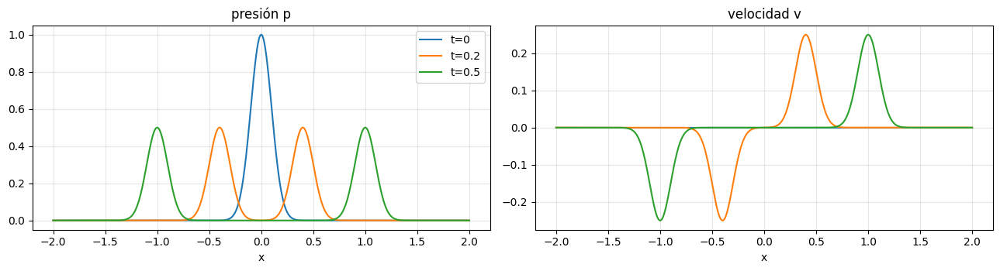

In [19]:
K, rho0 = 4.0, 1.0
A = np.array([[0, K], [1 / rho0, 0]])
c, Z = np.sqrt(K / rho0), rho0 * np.sqrt(K / rho0)
lam = np.array([-c, c])
R = np.array([[-Z, Z], [1.0, 1.0]])                 # columnas r_1, r_2 (como en las slides)
print("valores propios:", lam, "  c =", c, "  Z =", Z)
print("verificación A R = R Λ:", np.allclose(A @ R, R @ np.diag(lam)))

p0 = lambda x: np.exp(-50 * x**2); v0 = lambda x: 0 * x       # pulso de presion en reposo
def acustica(x, t):
    Rinv = np.linalg.inv(R)
    w = [Rinv[k, 0] * p0(x - lam[k] * t) + Rinv[k, 1] * v0(x - lam[k] * t) for k in range(2)]
    return R[0, 0] * w[0] + R[0, 1] * w[1], R[1, 0] * w[0] + R[1, 1] * w[1]

x = np.linspace(-2, 2, 800)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), sharex=True)
for t in [0, 0.2, 0.5]:
    p, v = acustica(x, t)
    axs[0].plot(x, p, label=f"t={t}"); axs[1].plot(x, v, label=f"t={t}")
axs[0].set(title="presión p", xlabel="x"); axs[1].set(title="velocidad v", xlabel="x")
axs[0].legend(); plt.tight_layout(); plt.show()

El pulso se separa en dos ondas que viajan con velocidades $\pm c$; en la onda que va a la derecha $p = Z v$ y en la que va a la izquierda $p = -Zv$.

## 7. Aguas someras (shallow water)

Con profundidad $\eta(x,t)$, velocidad $v(x,t)$ y gravedad $g$:
$$
\frac{\partial}{\partial t}\begin{bmatrix}\eta\\ \eta v\end{bmatrix} + \frac{\partial}{\partial x}\begin{bmatrix}\eta v\\ \eta v^2 + \tfrac12 g\eta^2\end{bmatrix} = 0,
\qquad \lambda_{1,2} = v \mp \sqrt{g\eta}.
$$
El sistema es estrictamente hiperbólico si $\eta>0$. El número de Froude es $\mathrm{Fr} = |v|/\sqrt{g\eta}$.

**Rotura de presa** (problema de Riemann): $\eta_L = 3$, $\eta_R = 1$, $v_L = v_R = 0$, $g=1$. La solución es una **1-rarefacción** hacia la izquierda y un **2-choque** hacia la derecha. El estado intermedio $(\eta_m, v_m)$ se obtiene de
$$
v_m = 2\big(\sqrt{g\eta_L}-\sqrt{g\eta_m}\big)\ \ (\text{invariante de Riemann}),\qquad
v_m = (\eta_m-\eta_R)\sqrt{\tfrac g2\,\tfrac{\eta_m+\eta_R}{\eta_m\eta_R}}\ \ (\text{Rankine–Hugoniot}).
$$

In [20]:
g, etaL, etaR = 1.0, 3.0, 1.0
cL = np.sqrt(g * etaL)
phi = lambda em: 2 * (cL - np.sqrt(g * em)) - (em - etaR) * np.sqrt(g / 2 * (em + etaR) / (em * etaR))
eta_m = brentq(phi, etaR, etaL)
c_m = np.sqrt(g * eta_m); v_m = 2 * (cL - c_m)
s = eta_m * v_m / (eta_m - etaR)                 # velocidad del choque (RH en la masa)
print(f"eta_m = {eta_m:.4f}, v_m = {v_m:.4f}, velocidad del choque s = {s:.4f}")
print(f"chequeo RH en el momento: {(eta_m*v_m**2 + g*eta_m**2/2 - g*etaR**2/2)/(eta_m*v_m):.4f}")
print(f"condición de Lax del 2-choque: v_m + c_m = {v_m + c_m:.3f} > s > sqrt(g eta_R) = {np.sqrt(g*etaR):.3f}")

def rotura_presa(x, t):
    xi = x / t
    eta = np.where(xi < -cL, etaL, etaR).astype(float); v = np.zeros_like(xi)
    fan = (xi >= -cL) & (xi < v_m - c_m)
    cc = (2 * cL - xi[fan]) / 3
    eta[fan] = cc**2 / g; v[fan] = 2 * (xi[fan] + cL) / 3
    mid = (xi >= v_m - c_m) & (xi < s)
    eta[mid] = eta_m; v[mid] = v_m
    return eta, v

eta_m = 1.8486, v_m = 0.7449, velocidad del choque s = 1.6226
chequeo RH en el momento: 1.6226
condición de Lax del 2-choque: v_m + c_m = 2.104 > s > sqrt(g eta_R) = 1.000


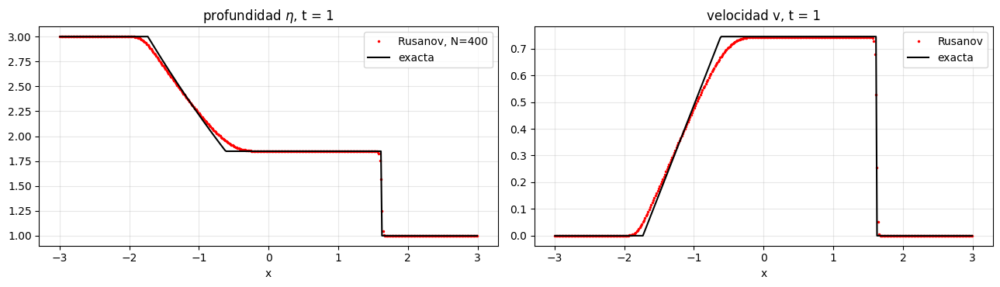

error L1 en eta: 7.718e-02


In [21]:
def flujo_sw(U):
    eta, m = U
    return np.array([m, m**2 / eta + g * eta**2 / 2])

def rusanov_sw(UL, UR):
    a = np.maximum(np.abs(UL[1] / UL[0]) + np.sqrt(g * UL[0]), np.abs(UR[1] / UR[0]) + np.sqrt(g * UR[0]))
    return 0.5 * (flujo_sw(UL) + flujo_sw(UR)) - 0.5 * a * (UR - UL)

def aguas_someras(N, T, intervalo=(-3, 3), CFL=0.9, guardar_cada=None):
    # Volumenes finitos con flujo de Rusanov (Clase 26) y bordes de extrapolacion.
    xL, xR = intervalo; h = (xR - xL) / N
    x = xL + h * (np.arange(N) + 0.5)
    U = np.array([np.where(x < 0, etaL, etaR), np.zeros(N)])
    t = 0.0; historia = [U.copy()]; tiempos = [0.0]
    while t < T - 1e-12:
        smax = np.max(np.abs(U[1] / U[0]) + np.sqrt(g * U[0]))
        dt = min(CFL * h / smax, T - t)
        Ue = np.concatenate([U[:, :1], U, U[:, -1:]], axis=1)
        F = rusanov_sw(Ue[:, :-1], Ue[:, 1:])
        U = U - dt / h * (F[:, 1:] - F[:, :-1]); t += dt
        historia.append(U.copy()); tiempos.append(t)
    return x, U, historia, np.array(tiempos)

T = 1.0
x, U, hist, tt = aguas_someras(400, T)
eta_ex, v_ex = rotura_presa(x, T)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(x, U[0], "r.", ms=3, label="Rusanov, N=400"); axs[0].plot(x, eta_ex, "k-", label="exacta")
axs[0].set(title=r"profundidad $\eta$, t = 1", xlabel="x"); axs[0].legend()
axs[1].plot(x, U[1] / U[0], "r.", ms=3, label="Rusanov"); axs[1].plot(x, v_ex, "k-", label="exacta")
axs[1].set(title="velocidad v, t = 1", xlabel="x"); axs[1].legend()
plt.tight_layout(); plt.show()
print(f"error L1 en eta: {np.sum(np.abs(U[0] - eta_ex)) * (x[1]-x[0]):.3e}")

In [22]:
# animacion de la rotura de presa
etas = [Uk[0] for Uk in hist]
animar(x, etas, tt, exacta=lambda xx, t: rotura_presa(xx, max(t, 1e-9))[0], ylim=(0.8, 3.2),
       paso=max(1, len(etas) // 60), titulo="Rotura de presa", estilo="-")

## 8. Dinámica de gases: ecuaciones de Euler

$$
\frac{\partial}{\partial t}\begin{bmatrix}\rho\\ \rho v\\ E\end{bmatrix} + \frac{\partial}{\partial x}\begin{bmatrix}\rho v\\ \rho v^2+p\\ v(E+p)\end{bmatrix} = 0,
\qquad E = \tfrac12\rho v^2 + \frac{p}{\gamma-1}\ \ (\text{gas politrópico}),
$$
con valores propios $v-c,\ v,\ v+c$ y velocidad del sonido $c = \sqrt{\gamma p/\rho}$.

**Tubo de choque de Sod** ($\gamma = 1.4$): $(\rho,v,p)_L = (1,0,1)$, $(\rho,v,p)_R = (0.125,0,0.1)$, diafragma en $x_0=0.5$, $t = 0.2$.
La solución tiene una rarefacción, una discontinuidad de contacto y un choque. La calculamos con el solucionador exacto de Riemann (Toro, cap. 4) y la comparamos con volúmenes finitos (flujo HLL).

In [23]:
gam = 1.4
WL, WR = (1.0, 0.0, 1.0), (0.125, 0.0, 0.1)

def fK(p, rK, pK):
    cK = np.sqrt(gam * pK / rK)
    if p > pK:                                     # choque
        A = 2 / ((gam + 1) * rK); B = (gam - 1) / (gam + 1) * pK
        return (p - pK) * np.sqrt(A / (p + B)), np.sqrt(A / (p + B)) * (1 - 0.5 * (p - pK) / (p + B))
    pr = p / pK                                    # rarefaccion
    return 2 * cK / (gam - 1) * (pr**((gam - 1) / (2 * gam)) - 1), 1 / (rK * cK) * pr**(-(gam + 1) / (2 * gam))

def estado_estrella(WL, WR):
    (rL, uL, pL), (rR, uR, pR) = WL, WR
    p = 0.5 * (pL + pR)
    for _ in range(50):                            # Newton sobre la funcion de presion
        fl, dl = fK(p, rL, pL); fr, dr = fK(p, rR, pR)
        dp = (fl + fr + uR - uL) / (dl + dr); p = max(p - dp, 1e-10)
        if abs(dp) < 1e-14: break
    fl, _ = fK(p, rL, pL); fr, _ = fK(p, rR, pR)
    return p, 0.5 * (uL + uR) + 0.5 * (fr - fl)

ps, us = estado_estrella(WL, WR)
rL, uL, pL = WL; rR, uR, pR = WR
cL = np.sqrt(gam * pL / rL)
rsL = rL * (ps / pL)**(1 / gam)
g1 = (gam - 1) / (gam + 1)
rsR = rR * (ps / pR + g1) / (g1 * ps / pR + 1)
S_choque = uR + np.sqrt(gam * pR / rR) * np.sqrt((gam + 1) / (2 * gam) * ps / pR + (gam - 1) / (2 * gam))
csL = cL * (ps / pL)**((gam - 1) / (2 * gam))
print(f"p* = {ps:.5f}, v* = {us:.5f}, rho*_L = {rsL:.5f}, rho*_R = {rsR:.5f}, velocidad del choque = {S_choque:.5f}")

def sod_exacta(x, t, x0=0.5):
    out = np.zeros((3, len(x)))
    for i, xi in enumerate((x - x0) / t):
        if xi < uL - cL:   W = (rL, uL, pL)
        elif xi < us - csL:
            u = 2 / (gam + 1) * (cL + (gam - 1) / 2 * uL + xi)
            c = 2 / (gam + 1) * (cL + (gam - 1) / 2 * (uL - xi))
            W = (rL * (c / cL)**(2 / (gam - 1)), u, pL * (c / cL)**(2 * gam / (gam - 1)))
        elif xi < us:      W = (rsL, us, ps)
        elif xi < S_choque: W = (rsR, us, ps)
        else:              W = (rR, uR, pR)
        out[:, i] = W
    return out

p* = 0.30313, v* = 0.92745, rho*_L = 0.42632, rho*_R = 0.26557, velocidad del choque = 1.75216


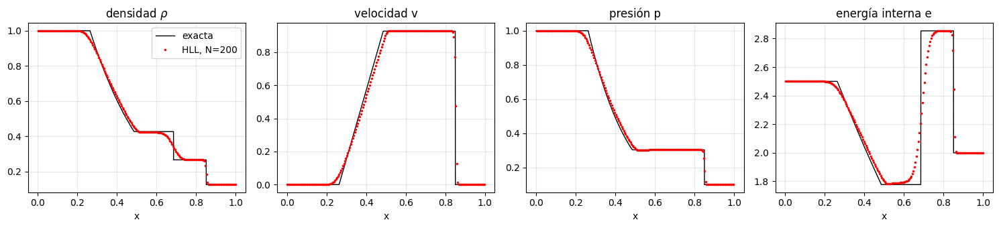

In [24]:
def primitivas(U):
    r = U[0]; v = U[1] / r; p = (gam - 1) * (U[2] - 0.5 * r * v**2)
    return r, v, p

def flujo_euler(U):
    r, v, p = primitivas(U)
    return np.array([r * v, r * v**2 + p, v * (U[2] + p)])

def hll(UL, UR):
    rl, vl, pl = primitivas(UL); rr, vr, pr = primitivas(UR)
    cl, cr = np.sqrt(gam * pl / rl), np.sqrt(gam * pr / rr)
    SL = np.minimum(vl - cl, vr - cr); SR = np.maximum(vl + cl, vr + cr)
    FL, FR = flujo_euler(UL), flujo_euler(UR)
    Fh = (SR * FL - SL * FR + SL * SR * (UR - UL)) / (SR - SL)
    return np.where(SL >= 0, FL, np.where(SR <= 0, FR, Fh))

def euler_vf(N, T=0.2, CFL=0.9):
    h = 1 / N; x = h * (np.arange(N) + 0.5)
    r = np.where(x < 0.5, rL, rR); p = np.where(x < 0.5, pL, pR); v = np.zeros(N)
    U = np.array([r, r * v, p / (gam - 1) + 0.5 * r * v**2]); t = 0.0
    while t < T - 1e-12:
        rr, vv, pp = primitivas(U)
        dt = min(CFL * h / np.max(np.abs(vv) + np.sqrt(gam * pp / rr)), T - t)
        Ue = np.concatenate([U[:, :1], U, U[:, -1:]], axis=1)
        F = hll(Ue[:, :-1], Ue[:, 1:])
        U = U - dt / h * (F[:, 1:] - F[:, :-1]); t += dt
    return x, U

x, U = euler_vf(200)
r, v, p = primitivas(U)
xf = np.linspace(0, 1, 2000); E = sod_exacta(xf, 0.2)
fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
datos = [(r, E[0], r"densidad $\rho$"), (v, E[1], "velocidad v"), (p, E[2], "presión p"),
         (p / ((gam - 1) * r), E[2] / ((gam - 1) * E[0]), "energía interna e")]
for ax, (num, ex, tit) in zip(axs, datos):
    ax.plot(xf, ex, "k-", lw=1, label="exacta"); ax.plot(x, num, "r.", ms=3, label="HLL, N=200")
    ax.set(title=tit, xlabel="x")
axs[0].legend(); plt.tight_layout(); plt.show()

**Observación.** El choque y la rarefacción quedan bien capturados; la **discontinuidad de contacto** (salto de $\rho$ y $e$ con $v$ y $p$ continuas) es la más difundida, porque no es compresiva: las características no convergen hacia ella. Esto motiva solucionadores como HLLC y los métodos de alta resolución (Clase 26).